In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('advertising.csv') 


# Посмотреть первые 5 строк
display(df.head()) 

# Общая информация о типах данных и пропусках
df.info() 

# Статистика по числовым признакам
display(df.describe()) 

print(f"Количество строк: {df.shape[0]}, Количество столбцов: {df.shape[1]}")

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   str    
 5   City                      1000 non-null   str    
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   str    
 8   Timestamp                 1000 non-null   str    
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 78.3 KB


,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,65.000200,36.009000,55000.000080,180.000100,0.481000,0.50000
std,15.853615,8.785562,13414.634022,43.902339,0.499889,0.50025
min,32.600000,19.000000,13996.500000,104.780000,0.000000,0.00000
25%,51.360000,29.000000,47031.802500,138.830000,0.000000,0.00000
50%,68.215000,35.000000,57012.300000,183.130000,0.000000,0.50000
75%,78.547500,42.000000,65470.635000,218.792500,1.000000,1.00000
max,91.430000,61.000000,79484.800000,269.960000,1.000000,1.00000


Количество строк: 1000, Количество столбцов: 10


In [2]:
# Удаляем текстовые описания и географические данные, оставляя только числовые/временные признаки
df = df.drop(['Ad Topic Line', 'City', 'Country'], axis=1)

print("Лишние столбцы удалены")
display(df.head())

Лишние столбцы удалены


,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,0,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,1,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,0,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,1,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,0,2016-06-03 03:36:18,0


In [3]:
num_df = df.select_dtypes(include=['int64', 'float64'])
cat_df = df.select_dtypes(include=['object'])

print(f"Числовые признаки ({num_df.shape[1]}): {list(num_df.columns)}")
print(f"Категориальные признаки ({cat_df.shape[1]}): {list(cat_df.columns)}")

Числовые признаки (6): ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male', 'Clicked on Ad']
Категориальные признаки (1): ['Timestamp']


C:\Users\Nickolay\AppData\Local\Temp\ipykernel_19256\2293459237.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_df = df.select_dtypes(include=['object'])


In [4]:
# Аналитика по количественным признакам
stats_numeric = pd.DataFrame({
    'min': num_df.min(),
    'max': num_df.max(),
    'mean': num_df.mean(),
    'median': num_df.median(),
    'variance': num_df.var(), # Дисперсия
    'quantile_0.1': num_df.quantile(0.1),
    'quantile_0.25': num_df.quantile(0.25),
    'quantile_0.75': num_df.quantile(0.75),
    'quantile_0.9': num_df.quantile(0.9)
})

display(stats_numeric)

,min,max,mean,median,variance,quantile_0.1,quantile_0.25,quantile_0.75,quantile_0.9
Daily Time Spent on Site,32.60,91.43,65.00020,68.215,2.513371e+02,41.343,51.3600,78.5475,83.892
Age,19.00,61.00,36.00900,35.000,7.718611e+01,26.000,29.0000,42.0000,49.000
Area Income,13996.50,79484.80,55000.00008,57012.300,1.799524e+08,35222.808,47031.8025,65470.6350,70505.613
Daily Internet Usage,104.78,269.96,180.00010,183.130,1.927415e+03,120.451,138.8300,218.7925,236.154
Male,0.00,1.00,0.48100,0.000,2.498889e-01,0.000,0.0000,1.0000,1.000
Clicked on Ad,0.00,1.00,0.50000,0.500,2.502503e-01,0.000,0.0000,1.0000,1.000


In [5]:
# Аналитика по категориальным признакам
if not cat_df.empty:
    cat_stats = pd.DataFrame({
        'unique_count': cat_df.nunique(),
        'mode': cat_df.mode().iloc[0]  # Мода (самое частое значение)
    })
# Преобразование категориальных признаков
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Year'] = df['Timestamp'].dt.year
df['Month'] = df['Timestamp'].dt.month
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek
df['Hour'] = df['Timestamp'].dt.hour
df = df.drop('Timestamp', axis=1)

display(df.head())

C:\Users\Nickolay\AppData\Local\Temp\ipykernel_19256\1942419462.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['DayOfWeek'] = df['Timestamp'].dt.dayofweek


,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Clicked on Ad,Year,Month,DayOfWeek,Hour
0,68.95,35,61833.90,256.09,0,0,2016,3,6,0
1,80.23,31,68441.85,193.77,1,0,2016,4,0,1
2,69.47,26,59785.94,236.50,0,0,2016,3,6,20
3,74.15,29,54806.18,245.89,1,0,2016,1,6,2
4,68.37,35,73889.99,225.58,0,0,2016,6,4,3


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# OLAP-анализ
# Фильтрация: женщины (Male==0), весна (3,4,5), выходные (5,6), утро (<12)
filtered_df = df[
    (df['Male'] == 0) & 
    (df['Month'].isin([3, 4, 5])) & 
    (df['DayOfWeek'].isin([5, 6])) & 
    (df['Hour'] < 12)
]

# Расчет метрик
if not filtered_df.empty:
    avg_age = filtered_df['Age'].mean()
    click_rate = filtered_df['Clicked on Ad'].mean() * 100
    avg_time_on_site = filtered_df['Daily Time Spent on Site'].mean()
    
    print("Результаты OLAP-анализа (куб)")
    print(f"Отфильтровано записей: {len(filtered_df)}")
    print(f"Средний возраст: {avg_age:.2f} лет")
    print(f"Доля кликнувших на объявление: {click_rate:.2f}%")
    print(f"Среднее время на сайте: {avg_time_on_site:.2f} минут")
else:
    print("Нет данных по заданным условиям фильтрации.")

# Сводная таблица
print("\nСреднее время на сайте по месяцам и дню недели")
cube_pivot = filtered_df.pivot_table(
    values='Daily Time Spent on Site',
    index='Month',
    columns='DayOfWeek',
    aggfunc='mean',
    fill_value=0
)
cube_pivot.index = cube_pivot.index.map({3: 'Март', 4: 'Апрель', 5: 'Май'})
cube_pivot.columns = cube_pivot.columns.map({5: 'Суббота', 6: 'Воскресенье'})
display(cube_pivot)

Результаты OLAP-анализа (куб)
Отфильтровано записей: 28
Средний возраст: 36.46 лет
Доля кликнувших на объявление: 53.57%
Среднее время на сайте: 63.99 минут

Среднее время на сайте по месяцам и дню недели


DayOfWeek,Суббота,Воскресенье
Month,,
Март,73.938,58.756000
Апрель,75.690,52.621667
Май,0.000,63.716250


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Разделение на признаки и целевую переменную
X = df.drop('Clicked on Ad', axis=1)
y = df['Clicked on Ad']

print(f"Признаки (X): {X.shape}")
print(f"Целевая переменная (y): {y.shape}")

# Создание возрастных групп
if 'Age_Group' not in X.columns:
    X['Age_Group'] = pd.cut(X['Age'], 
                             bins=[0, 25, 35, 50, 100], 
                             labels=['18-25', '26-35', '36-50', '51+'])
    print("Столбец Age_Group создан")
else:
    print("Столбец Age_Group уже существует")

# Кодирование категориальных признаков
X = pd.get_dummies(X, columns=['Age_Group'], prefix='Age', drop_first=True)

print(f"\nПосле кодирования: {X.shape}")
print(f"Признаки: {list(X.columns)}")

# Разделение 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\nОбучающая выборка: {X_train.shape[0]} записей")
print(f"Тестовая выборка: {X_test.shape[0]} записей")

# Масштабирование числовых признаков
scaler = StandardScaler()

# Автоматически определяем числовые столбцы
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"\nЧисловые столбцы для масштабирования: {num_cols}")

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("\nДанные готовы")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

Признаки (X): (1000, 9)
Целевая переменная (y): (1000,)
Столбец Age_Group создан

После кодирования: (1000, 12)
Признаки: ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male', 'Year', 'Month', 'DayOfWeek', 'Hour', 'Age_26-35', 'Age_36-50', 'Age_51+']

Обучающая выборка: 800 записей
Тестовая выборка: 200 записей

Числовые столбцы для масштабирования: ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']

Данные готовы
X_train: (800, 12)
X_test: (200, 12)


Обучение модели: Дерево решений

Точность (Accuracy): 0.9650
Точность (Precision): 0.9604
Полнота (Recall): 0.9700
F1-мера: 0.9652

Отчет по классификации:
              precision    recall  f1-score   support

           0       0.97      0.96      0.96       100
           1       0.96      0.97      0.97       100

    accuracy                           0.96       200
   macro avg       0.97      0.96      0.96       200
weighted avg       0.97      0.96      0.96       200



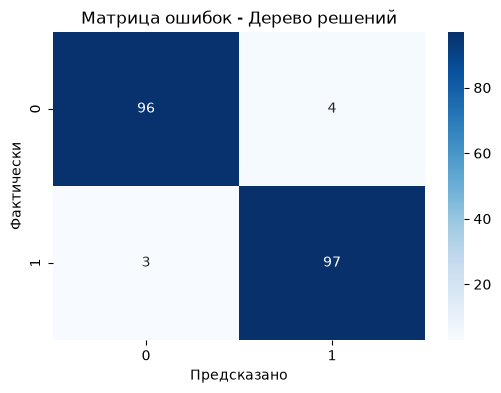

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Дерево решений
print("Обучение модели: Дерево решений\n")

# Инициализация модели
dt_model = DecisionTreeClassifier(random_state=42, max_depth=5, min_samples_split=10)

# Обучение
dt_model.fit(X_train, y_train)

# Предсказания
y_pred_dt = dt_model.predict(X_test)

# Оценка качества
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print(f"Точность (Accuracy): {accuracy_dt:.4f}")
print(f"Точность (Precision): {precision_dt:.4f}")
print(f"Полнота (Recall): {recall_dt:.4f}")
print(f"F1-мера: {f1_dt:.4f}")

print("\nОтчет по классификации:")
print(classification_report(y_test, y_pred_dt))

# Матрица ошибок
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues')
plt.title('Матрица ошибок - Дерево решений')
plt.xlabel('Предсказано')
plt.ylabel('Фактически')
plt.show()


Обучение модели: Логистическая регрессия

Точность (Accuracy): 0.9750
Точность (Precision): 0.9897
Полнота (Recall): 0.9600
F1-мера: 0.9746

Отчет по классификации:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       100
           1       0.99      0.96      0.97       100

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200



c:\Users\Nickolay\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


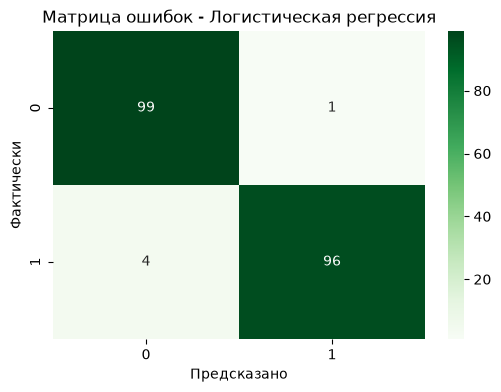

In [9]:
from sklearn.linear_model import LogisticRegression

# Логистическая регрессия
print("Обучение модели: Логистическая регрессия\n")

# Инициализация модели
lr_model = LogisticRegression(random_state=42, max_iter=1000, C=1.0)

# Обучение
lr_model.fit(X_train, y_train)

# Предсказания
y_pred_lr = lr_model.predict(X_test)

# Оценка качества
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print(f"Точность (Accuracy): {accuracy_lr:.4f}")
print(f"Точность (Precision): {precision_lr:.4f}")
print(f"Полнота (Recall): {recall_lr:.4f}")
print(f"F1-мера: {f1_lr:.4f}")

print("\nОтчет по классификации:")
print(classification_report(y_test, y_pred_lr))

# Матрица ошибок
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens')
plt.title('Матрица ошибок - Логистическая регрессия')
plt.xlabel('Предсказано')
plt.ylabel('Фактически')
plt.show()

Нейросеть (MLP)

Точность (Accuracy): 0.9750
Точность (Precision): 0.9897
Полнота (Recall): 0.9600
F1-мера: 0.9746

Отчет по классификации:
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       100
           1       0.99      0.96      0.97       100

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200



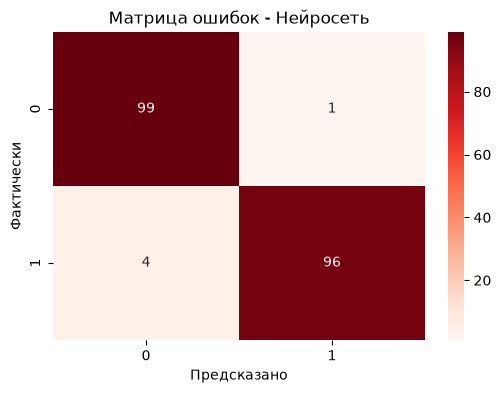

In [10]:
from sklearn.neural_network import MLPClassifier

# Нейросеть (MLPClassifier)
print("Нейросеть (MLP)\n")

# Инициализация модели
# hidden_layer_sizes=(100, 50) - два скрытых слоя
nn_model = MLPClassifier(
    hidden_layer_sizes=(100, 50), 
    max_iter=1000, 
    random_state=42,
    activation='relu',
    solver='adam'
)

# Обучение
nn_model.fit(X_train, y_train)

# Предсказания
y_pred_nn = nn_model.predict(X_test)

# Оценка качества
accuracy_nn = accuracy_score(y_test, y_pred_nn)
precision_nn = precision_score(y_test, y_pred_nn)
recall_nn = recall_score(y_test, y_pred_nn)
f1_nn = f1_score(y_test, y_pred_nn)

print(f"Точность (Accuracy): {accuracy_nn:.4f}")
print(f"Точность (Precision): {precision_nn:.4f}")
print(f"Полнота (Recall): {recall_nn:.4f}")
print(f"F1-мера: {f1_nn:.4f}")

print("\nОтчет по классификации:")
print(classification_report(y_test, y_pred_nn))

# Матрица ошибок
cm_nn = confusion_matrix(y_test, y_pred_nn)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_nn, annot=True, fmt='d', cmap='Reds')
plt.title('Матрица ошибок - Нейросеть')
plt.xlabel('Предсказано')
plt.ylabel('Фактически')
plt.show()


Сравнение качества моделей



,Модель,Accuracy,Precision,Recall,F1-score
0,Дерево решений,0.965,0.9604,0.97,0.9652
1,Логистическая регрессия,0.975,0.9897,0.96,0.9746
2,Нейросеть (MLP),0.975,0.9897,0.96,0.9746


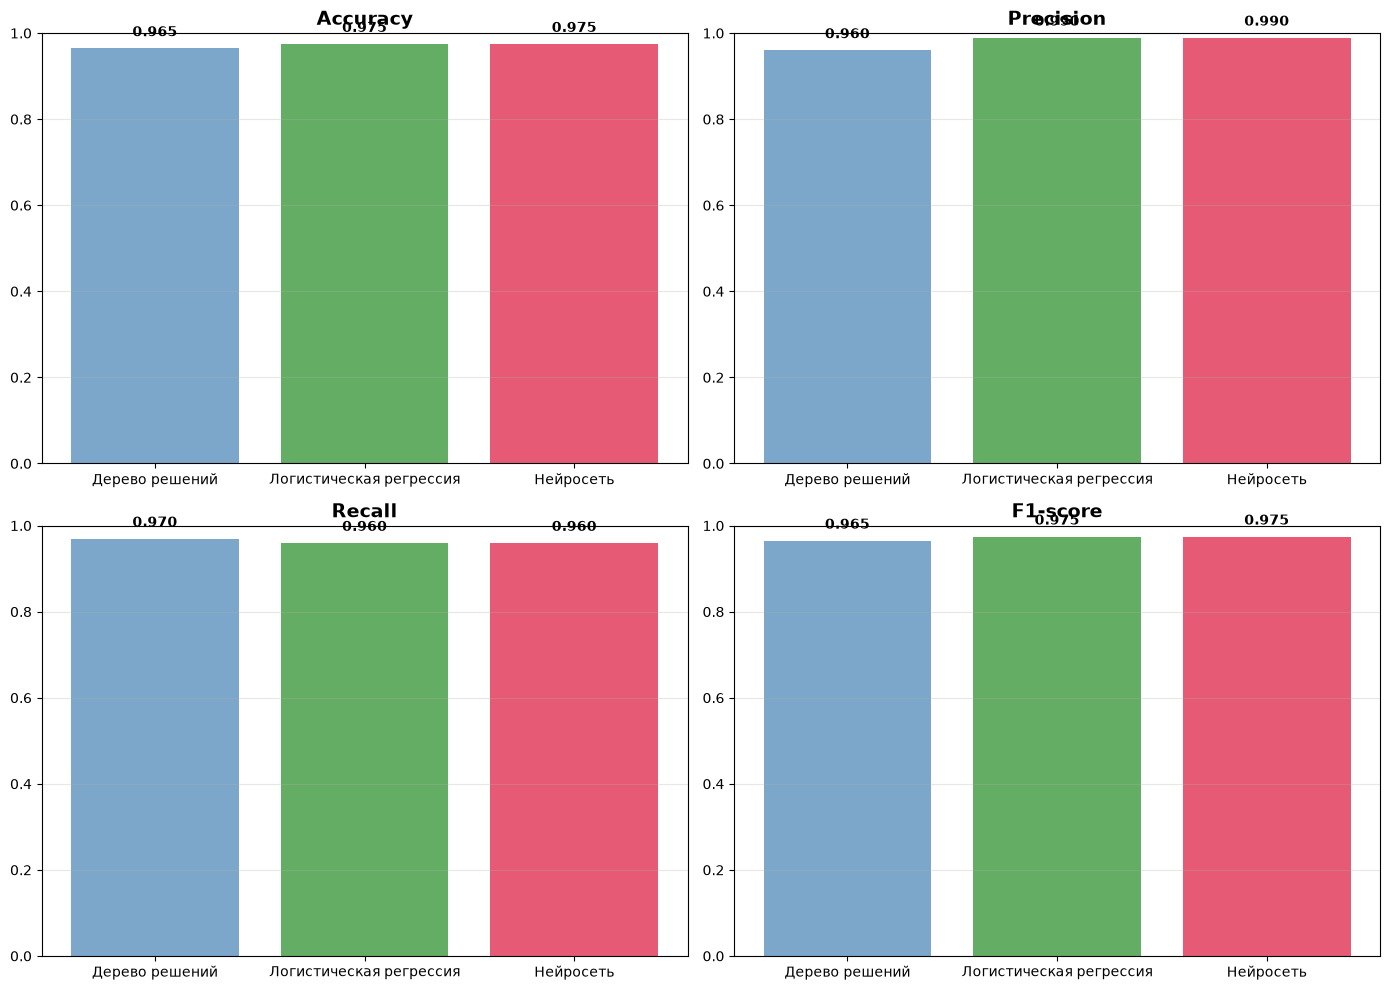


Лучшая модель по Accuracy: Логистическая регрессия (0.9750)


In [11]:
# Оценка качества и сравнение моделей
print("Сравнение качества моделей\n")

# Сводная таблица результатов
comparison_df = pd.DataFrame({
    'Модель': ['Дерево решений', 'Логистическая регрессия', 'Нейросеть (MLP)'],
    'Accuracy': [accuracy_dt, accuracy_lr, accuracy_nn],
    'Precision': [precision_dt, precision_lr, precision_nn],
    'Recall': [recall_dt, recall_lr, recall_nn],
    'F1-score': [f1_dt, f1_lr, f1_nn]
})

display(comparison_df.round(4))

# Визуализация сравнения
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

models = ['Дерево решений', 'Логистическая регрессия', 'Нейросеть']
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
values = [
    [accuracy_dt, accuracy_lr, accuracy_nn],
    [precision_dt, precision_lr, precision_nn],
    [recall_dt, recall_lr, recall_nn],
    [f1_dt, f1_lr, f1_nn]
]

colors = ['steelblue', 'forestgreen', 'crimson']

for idx, (metric, vals) in enumerate(zip(metrics, values)):
    ax = axes[idx // 2, idx % 2]
    bars = ax.bar(models, vals, color=colors, alpha=0.7)
    ax.set_title(metric, fontsize=14, fontweight='bold')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
    
    # Добавляем значения на столбцы
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
                f'{val:.3f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Определение лучшей модели
best_model_idx = comparison_df['Accuracy'].idxmax()
best_model = comparison_df.loc[best_model_idx, 'Модель']
best_accuracy = comparison_df.loc[best_model_idx, 'Accuracy']

print(f"\nЛучшая модель по Accuracy: {best_model} ({best_accuracy:.4f})")

In [ ]:
import os
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Загрузка и предобработка
df = pd.read_csv("advertising.csv")
df = df.drop(['Ad Topic Line', 'City', 'Country'], axis=1)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Month'] = df['Timestamp'].dt.month
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek
df['Hour'] = df['Timestamp'].dt.hour
df = df.drop('Timestamp', axis=1)

FEATURES = [
    'Daily Time Spent on Site', 'Age', 'Area Income',
    'Daily Internet Usage', 'Male', 'Month', 'DayOfWeek', 'Hour'
]
X = df[FEATURES]
y = df['Clicked on Ad']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

os.makedirs("models", exist_ok=True)

pipelines = {
    "lr": ("Логистическая регрессия (LR)", make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, random_state=42))),
    "dt": ("Дерево решений (DT)", make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=5, random_state=42))),
    "mlp": ("Нейросеть (MLP)", make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42))),
}

metrics_summary = {}
for key, (name, pipe) in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    metrics_summary[key] = {
        "name": name,
        "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
        "precision": round(float(precision_score(y_test, y_pred)), 4),
        "recall": round(float(recall_score(y_test, y_pred)), 4),
        "f1": round(float(f1_score(y_test, y_pred)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, y_prob)), 4),
        "y_test": y_test.tolist(),
        "y_pred": y_pred.tolist()
    }
    joblib.dump(pipe, f"models/{key}_pipeline.joblib")

joblib.dump(metrics_summary, "models/metrics_summary.joblib")


C:\Users\Nickolay\AppData\Local\Temp\ipykernel_19256\1766423538.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['DayOfWeek'] = df['Timestamp'].dt.dayofweek


✅ Все 3 модели и метрики сохранены в папку models/!
